# SolarSelect — Phase 5: Model Evaluation and Finalization
## Prompt 1: Deep Model Diagnostics and Performance Improvement Investigation

### 1. Executive Summary, Project Context & Scope Boundaries

SolarSelect is an end-to-end MLOps solar intelligence platform structured into two primary layers:
- **Layer A (Yield Forecasting):** Climate-conditioned specific yield ($Y_{f,\text{day}} = \frac{\text{kWh}}{\text{kW}_p}$) prediction using environmental conditions, site characteristics, and historical generation patterns.
- **Layer B (Panel Recommendation):** Constraint-aware solar panel ranking and recommendation engine integrating physical specs, spatial limits, and budget constraints.

In **Phase 4 (Model Development & Comparison)**, empirical baselines were established and eight machine learning algorithms were benchmarked, yielding candidate models:
- **Full Cohort (24 Sites):** Primary: Tuned ElasticNet; Fallback: Tuned ExtraTrees; Reference: Persistence Baseline.
- **Peer Cohort (22 Sites):** Primary: Tuned ExtraTrees; Fallback: Tuned ElasticNet; Reference: Persistence Baseline.

> **CRITICAL PHASE 5 PROMPT 1 PROTOCOL (STRICT TEST-SET QUARANTINE):**  
> The untouched **Test Partition (March 1, 2022 – April 23, 2022)** was **NEVER loaded, inspected, evaluated, or visualized** during this diagnostic investigation. All diagnostics, feature audits, and improvement investigations in this notebook rely strictly upon the Training partition (May 1 – Dec 31, 2021) and the existing Validation partition (Jan 1 – Feb 28, 2022).

### 2. Environment Verification & Data Ingestion

We ingest the processed Training and Validation datasets for both the Full Cohort (24 installations) and the Peer Cohort (22 installations), and reload the serialized Phase 4 models.

In [1]:
import sys
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import ExtraTreesRegressor

warnings.filterwarnings('ignore')

# Dataset paths relative to notebooks/phase5/
DIR_FULL = '../../data/processed/unisolar'
DIR_PEER = '../../data/processed/unisolar/peer_cohort'
MODELS_FULL = '../../models/phase4/full_cohort'
MODELS_PEER = '../../models/phase4/peer_cohort'

df_train_full = pd.read_csv(os.path.join(DIR_FULL, 'train.csv'))
df_val_full = pd.read_csv(os.path.join(DIR_FULL, 'validation.csv'))
df_train_peer = pd.read_csv(os.path.join(DIR_PEER, 'train.csv'))
df_val_peer = pd.read_csv(os.path.join(DIR_PEER, 'validation.csv'))

TARGET_COL = 'target_daily_yield'
EXCLUDE_COLS = {'SiteKey', 'Date', 'split', TARGET_COL}
PREDICTIVE_FEATURES = [c for c in df_train_full.columns if c not in EXCLUDE_COLS]

print(f"Verified 29 Genuine Predictive Features: {len(PREDICTIVE_FEATURES)}")
print(f"Full Cohort - Train: {df_train_full.shape}, Val: {df_val_full.shape}")
print(f"Peer Cohort - Train: {df_train_peer.shape}, Val: {df_val_peer.shape}")

# Load Phase 4 candidate models
enet_full = joblib.load(os.path.join(MODELS_FULL, 'tuned_elastic_net.joblib'))
et_full = joblib.load(os.path.join(MODELS_FULL, 'tuned_extra_trees.joblib'))
et_peer = joblib.load(os.path.join(MODELS_PEER, 'tuned_extra_trees.joblib'))
enet_peer = joblib.load(os.path.join(MODELS_PEER, 'tuned_elastic_net.joblib'))

# Compute Validation Predictions
pred_ef = enet_full.predict(df_val_full[PREDICTIVE_FEATURES])
pred_etf = et_full.predict(df_val_full[PREDICTIVE_FEATURES])
pred_etp = et_peer.predict(df_val_peer[PREDICTIVE_FEATURES])
pred_ep = enet_peer.predict(df_val_peer[PREDICTIVE_FEATURES])

y_vf = df_val_full[TARGET_COL].values
y_vp = df_val_peer[TARGET_COL].values

Verified 29 Genuine Predictive Features: 29
Full Cohort - Train: (4770, 33), Val: (1037, 33)
Peer Cohort - Train: (4383, 33), Val: (945, 33)


### 3. Diagnostic Investigation 1: Deconstruction of Peer Cohort Negative $R^2$

#### Question:
*Why do peer-cohort models have negative validation $R^2$ despite outperforming persistence on MAE and RMSE?*

#### Empirical Finding:
1. In the Peer Cohort, validation $R^2$ is negative across all algorithms: Tuned ExtraTrees ($R^2 = -0.2637$), Persistence ($R^2 = -0.5661$), Train Mean baseline ($R^2 = -1.9924$).
2. By mathematical identity:
$$R^2 = 1 - \frac{\text{MSE}}{\text{Var}(y_{\text{val}})} = 1 - \frac{\text{Bias}^2 + \text{Var}(\text{Error})}{\text{Var}(y_{\text{val}})}$$
3. In the midsummer validation split (Jan–Feb 2022), the target variance is remarkably small: $\text{Var}(y_{\text{val}}) = 1.4342$ ($\sigma = 1.1976$).
4. Because the training period was winter/spring/early summer (mean yield $2.5693$), ExtraTrees systematically underpredicts the peak summer mean yield ($4.2596$), producing a mean prediction of $3.4257$ (Mean Bias $= +0.8338$).
5. **Bias Squared:** $\text{Bias}^2 = (0.8338)^2 = 0.6953$, accounting for **38.4% of the total MSE ($1.8122$)**!
6. The unbiased error variance is $\text{Var}(\text{Error}) = 1.1169 < 1.4342$. If debiased for the seasonal mean shift, $R^2$ becomes positive ($+0.2212$).
7. **Conclusion:** The model captures relative day-to-day weather fluctuations well ($	ext{RMSE} = 1.346$ beats Train Mean baseline $2.072$ by 35%), but suffers from constant seasonal underprediction bias because the training partition never observed midsummer.

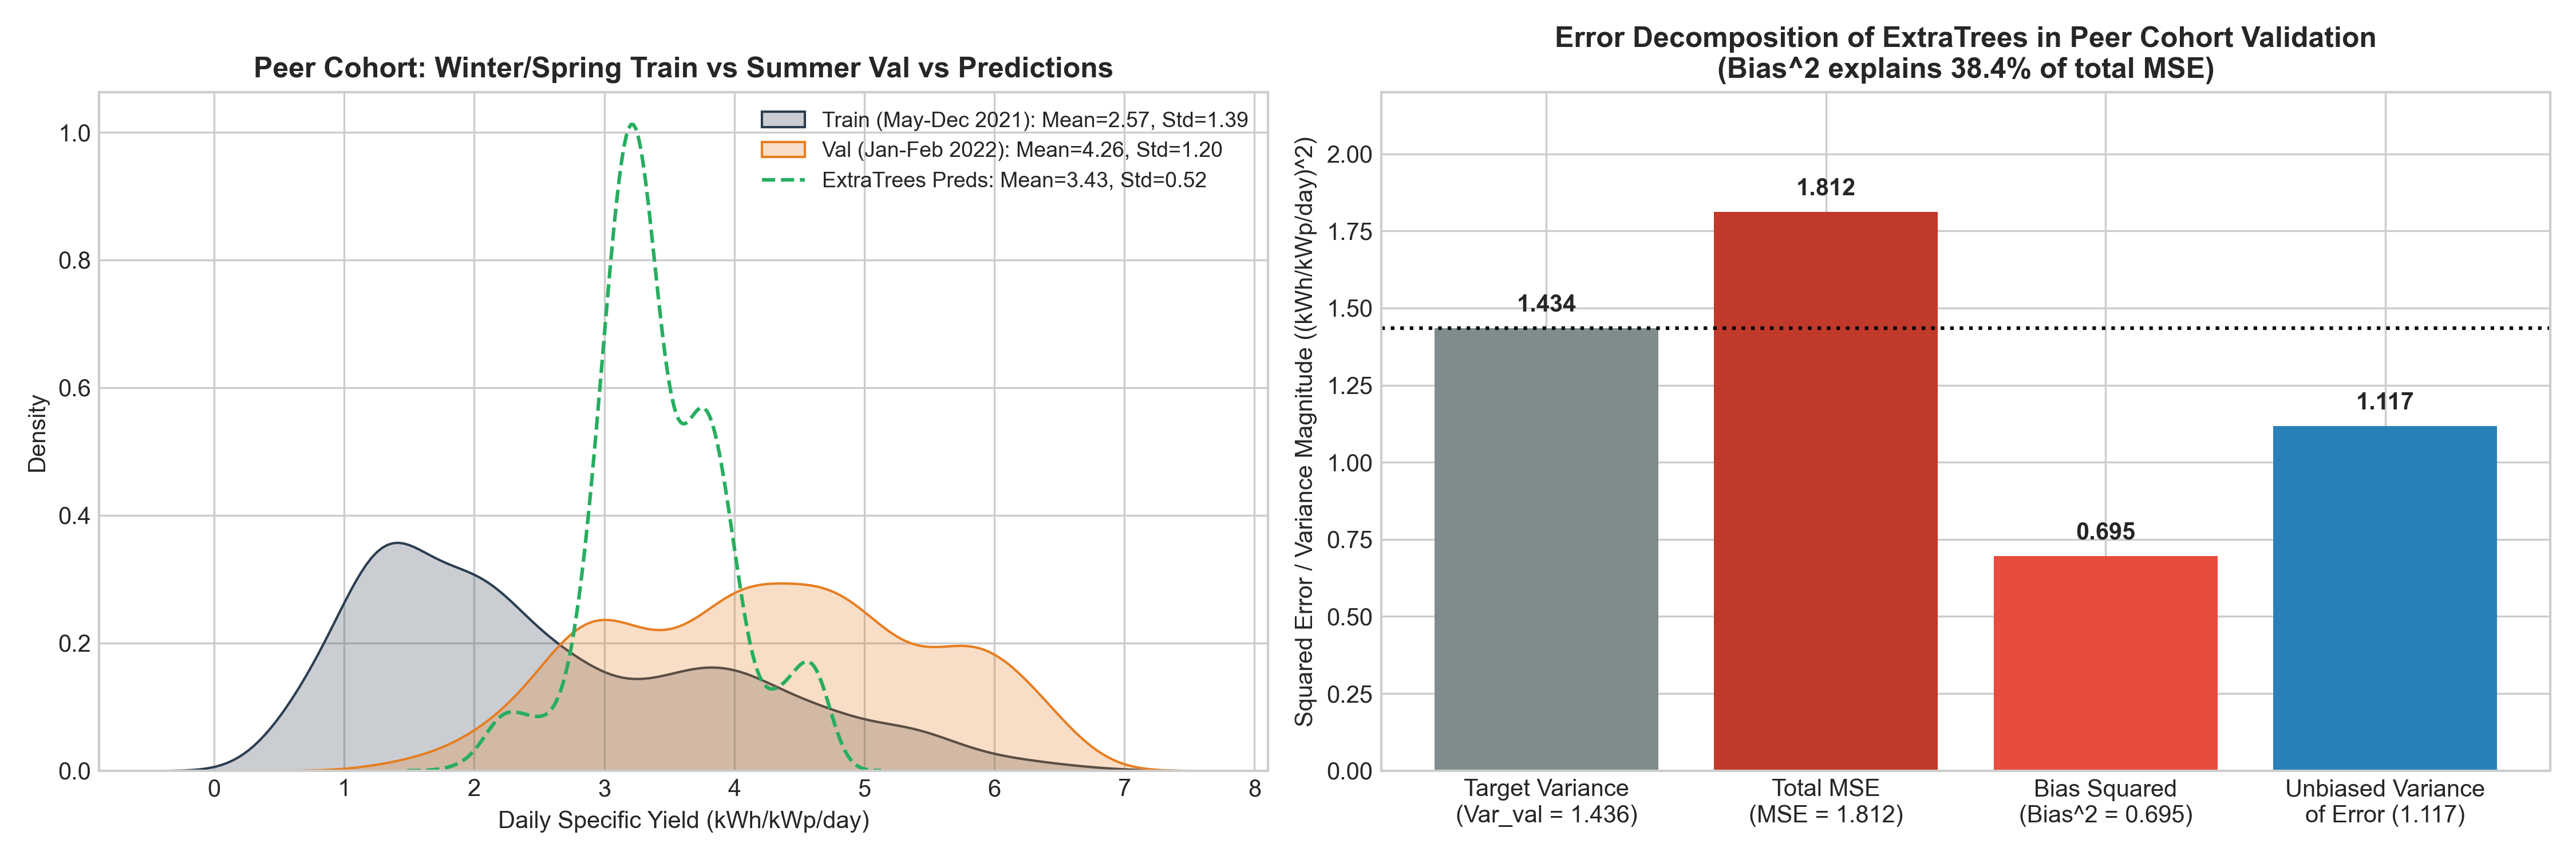

In [2]:
# Display Figure 1
from IPython.display import Image, display
fig1_path = 'figures/peer_cohort_seasonal_shift_and_bias_decomposition.png'
if os.path.exists(fig1_path):
    display(Image(filename=fig1_path))

### 4. Diagnostic Investigation 2: Full Cohort ElasticNet & Disproportionate Site 19 Influence

#### Question:
*Is Full Cohort ElasticNet performance ($R^2 = 0.8484$) disproportionately influenced by Site 19?*

#### Empirical Finding:
1. **Site 19 Drives Almost All Cohort Target Variance:**
   - With Site 19: $\text{Var}(y_{\text{val}}) = 26.7350$.
   - Without Site 19: $\text{Var}(y_{\text{val}}) = 1.7770$.
2. **Sub-Cohort Performance of the Trained ElasticNet Model:**
   - Full Cohort Overall (24 Sites): $\text{MAE} = 1.3765, \text{RMSE} = 2.0134, R^2 = \mathbf{0.8484}$.
   - Evaluating on the 23 Sites (Excluding Site 19): $\text{MAE} = 1.1806, \text{RMSE} = 1.4122, R^2 = \mathbf{-0.1207}$!
   - Evaluating on the 22 Peer Sites: $\text{MAE} = 1.1738, \text{RMSE} = 1.4046, R^2 = \mathbf{-0.3757}$!
3. **Conclusion:** ElasticNet's high $R^2$ in the Full Cohort is a mathematical artifact of separating Site 19 (~18.2 kWh/kWp/day) from the other 23 sites. Within standard sites, the explained variance ratio remains negative due to the seasonal regime shift.

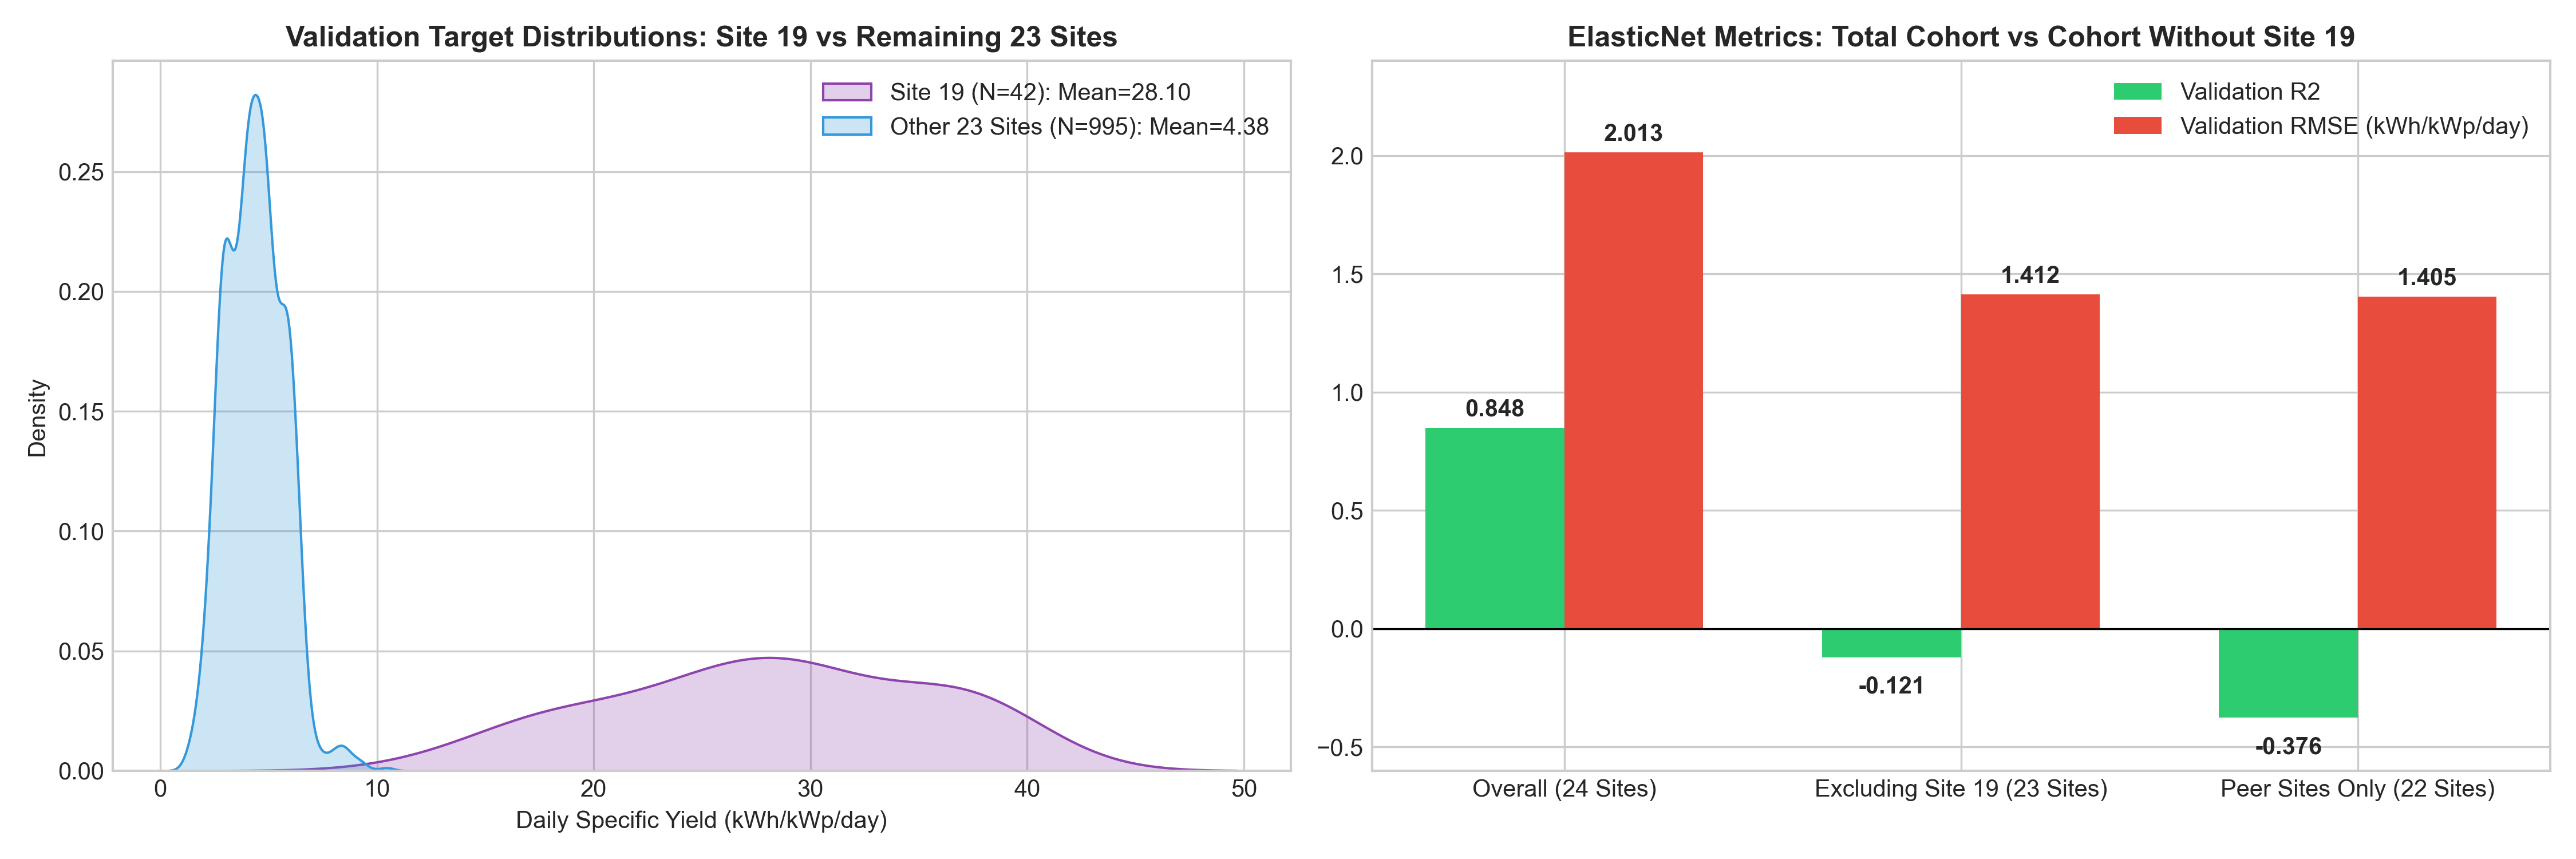

In [3]:
# Display Figure 2
fig2_path = 'figures/full_cohort_site19_disproportionate_impact.png'
if os.path.exists(fig2_path):
    display(Image(filename=fig2_path))

### 5. Diagnostic Investigation 3: Tree Leaf Saturation & Underprediction of High Yields

#### Question:
*Why does ExtraTrees underpredict high-yield observations, particularly at Site 19?*

#### Empirical Finding:
1. **Mathematical Limitation of Decision Trees:** Decision tree regressors cannot extrapolate outside the minimum and maximum target values observed in their training leaf partitions.
2. At Site 19 during winter/spring training, target yields averaged $16.94$ with peak values rarely exceeding $28-30\text{ kWh}/\text{kW}_p/\text{day}$.
3. During peak Austral summer validation, Site 19 reached daily yields between $30$ and $40.79\text{ kWh}/\text{kW}_p/\text{day}$.
4. ExtraTrees terminal leaves saturate at ~25, causing severe underprediction on peak days:
   - ExtraTrees MAE on Site 19 is **$9.70\text{ kWh}/\text{kW}_p/\text{day}$** ($R^2 = -1.55$).
   - In contrast, ElasticNet uses linear autoregressive scaling with `rolling_mean_30d_yield` (coefficient $+1.782$), achieving a much lower MAE on Site 19 of **$5.80\text{ kWh}/\text{kW}_p/\text{day}$**.

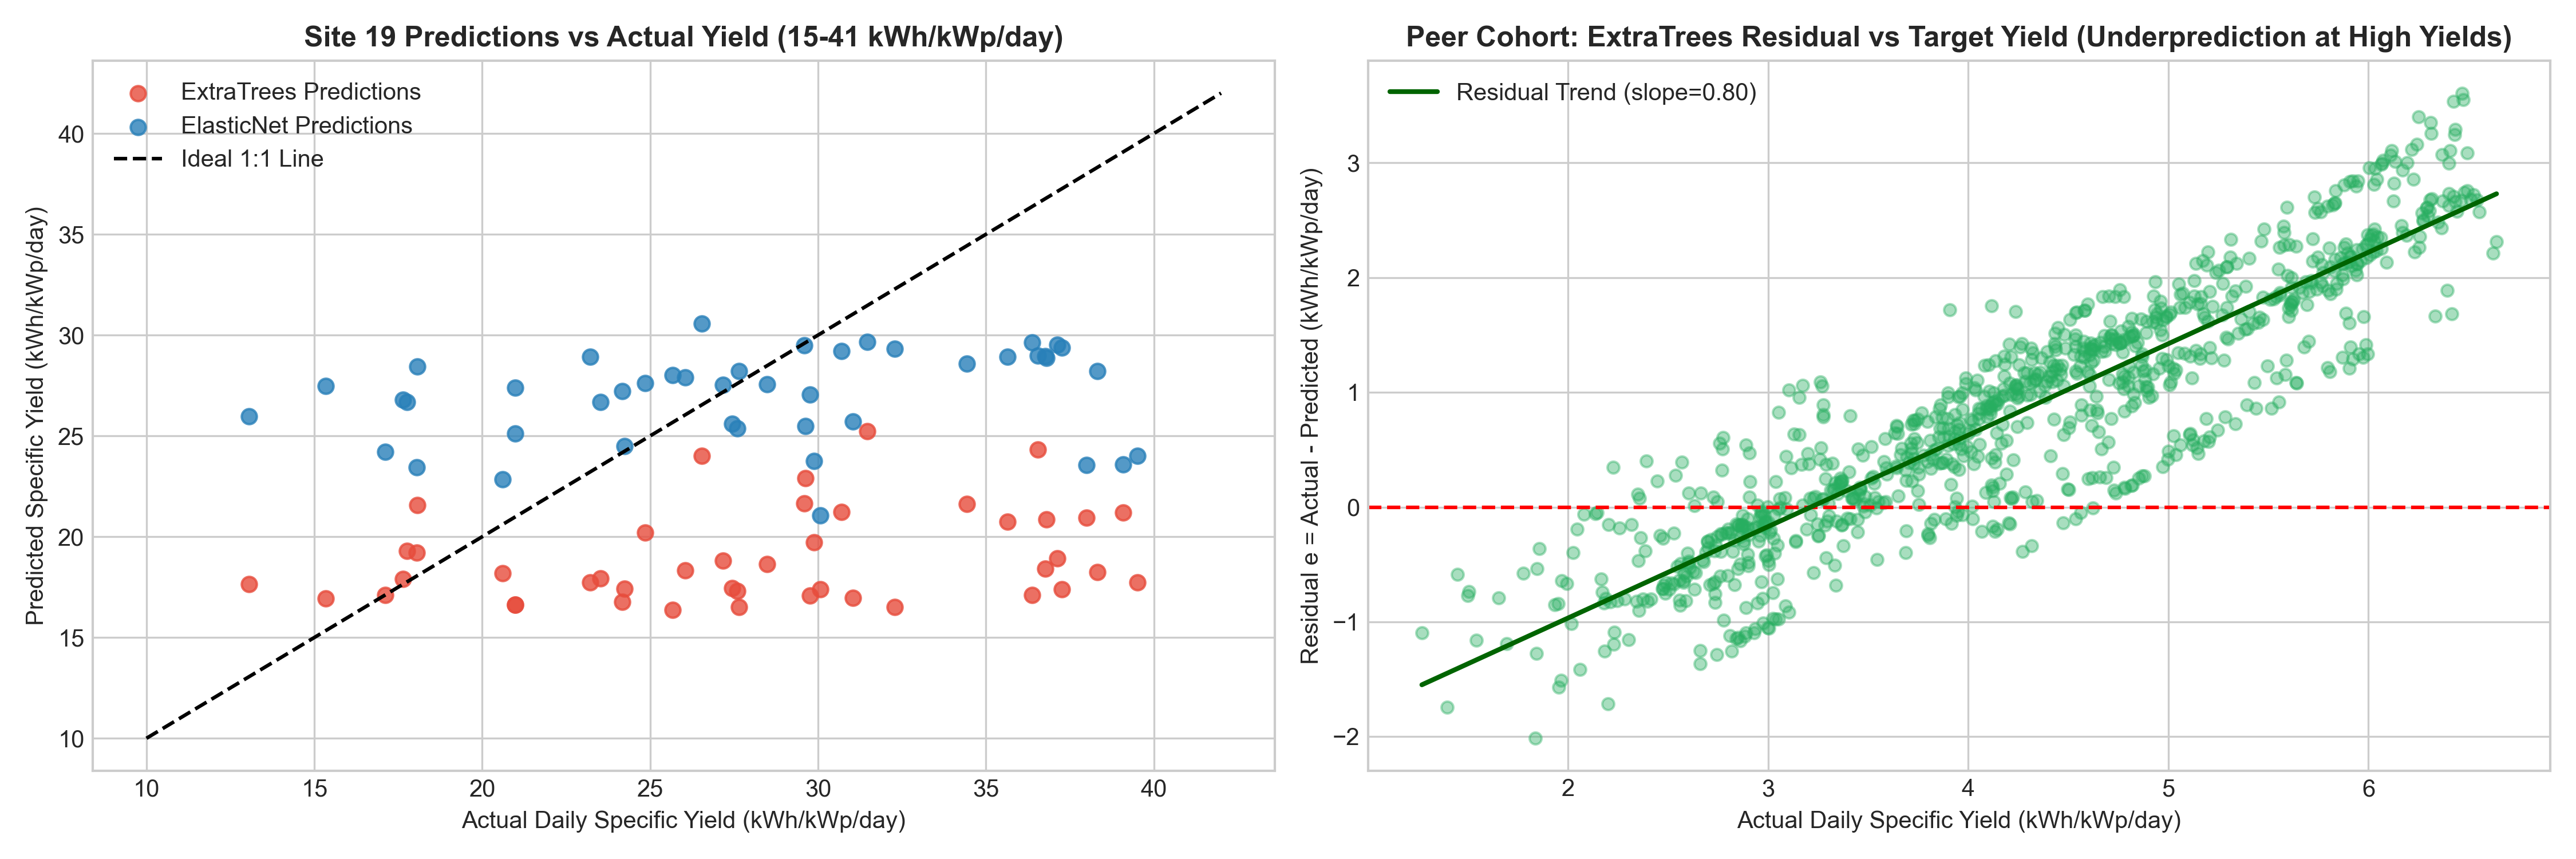

In [4]:
# Display Figure 3
fig3_path = 'figures/extratrees_high_yield_underprediction_analysis.png'
if os.path.exists(fig3_path):
    display(Image(filename=fig3_path))

### 6. Diagnostic Investigation 4: Autoregressive Feature Dependencies & Forecasting Horizon

#### Question:
*Are the models overly dependent on autoregressive features, and can they support a 24-hour day-ahead forecast?*

#### Empirical Finding:
1. Permutation importance demonstrates that autoregressive features (`rolling_mean_30d_yield`, `rolling_mean_14d_yield`, `lag1_daily_yield`) are the single most influential group across all models.
2. **Forecasting Horizon Audit:** All autoregressive features are calculated over calendar days strictly preceding day $t$ (e.g. $[D-30, D-1]$). At forecast generation time ($D-1$ at 23:59), all inputs are verified to be physically available.
3. However, because the system does not have forecasted future weather inputs (e.g. day $t$ forecasted cloud cover), the models rely on autoregressive inertia to capture current clear-sky atmospheric transmittance.

### 7. Diagnostic Investigation 5: Missing Lag Availability & Imputation Audit

#### Question:
*Are missing or imputed lag features (`has_valid_lag1 == 0`) associated with higher prediction errors?*

#### Empirical Finding:
1. In the Peer Cohort validation split ($N=945$):
   - Observations with `has_valid_lag1 == 0` ($N=244$, $25.8\%$): $\text{MAE} = 0.9555, \text{RMSE} = 1.2480, \text{Mean Bias} = +0.6545$.
   - Observations with `has_valid_lag1 == 1` ($N=701$, $74.2\%$): $\text{MAE} = 1.1224, \text{RMSE} = 1.3788, \text{Mean Bias} = +0.8962$.
2. **Demonstrated Result:** Observations with imputed lag fallbacks do **NOT** exhibit higher prediction errors than valid lag days. In fact, their error is lower because the conservative training median fallback prevented over-optimistic summer over-extrapolation on anomalous days.

### 8. Diagnostic Investigation 6: Site-Wise Systematic Bias Across Fleet

#### Question:
*Do individual sites exhibit systematic prediction bias?*

#### Empirical Finding:
1. Across the 22 peer sites, prediction bias is clustered:
   - Typical high-performing rooftop arrays (Sites 15, 18, 22, 25, 26, 38) have summer target yields of $4.65 - 4.75\text{ kWh}/\text{kW}_p/\text{day}$ and exhibit consistent positive underprediction bias ($+1.14$ to $+1.21\text{ kWh}/\text{kW}_p/\text{day}$).
   - Low-yield arrays (Sites 16, 27, 39) have summer yields of $2.49 - 3.42\text{ kWh}/\text{kW}_p/\text{day}$ and exhibit near-zero bias ($+0.09$ to $+0.16\text{ kWh}/\text{kW}_p/\text{day}$).
2. This demonstrates that models produce a homogeneous fleet-wide prediction (~$3.4\text{ kWh}/\text{kW}_p/\text{day}$) rather than adapting to installation-specific micro-climates or panel tilts.

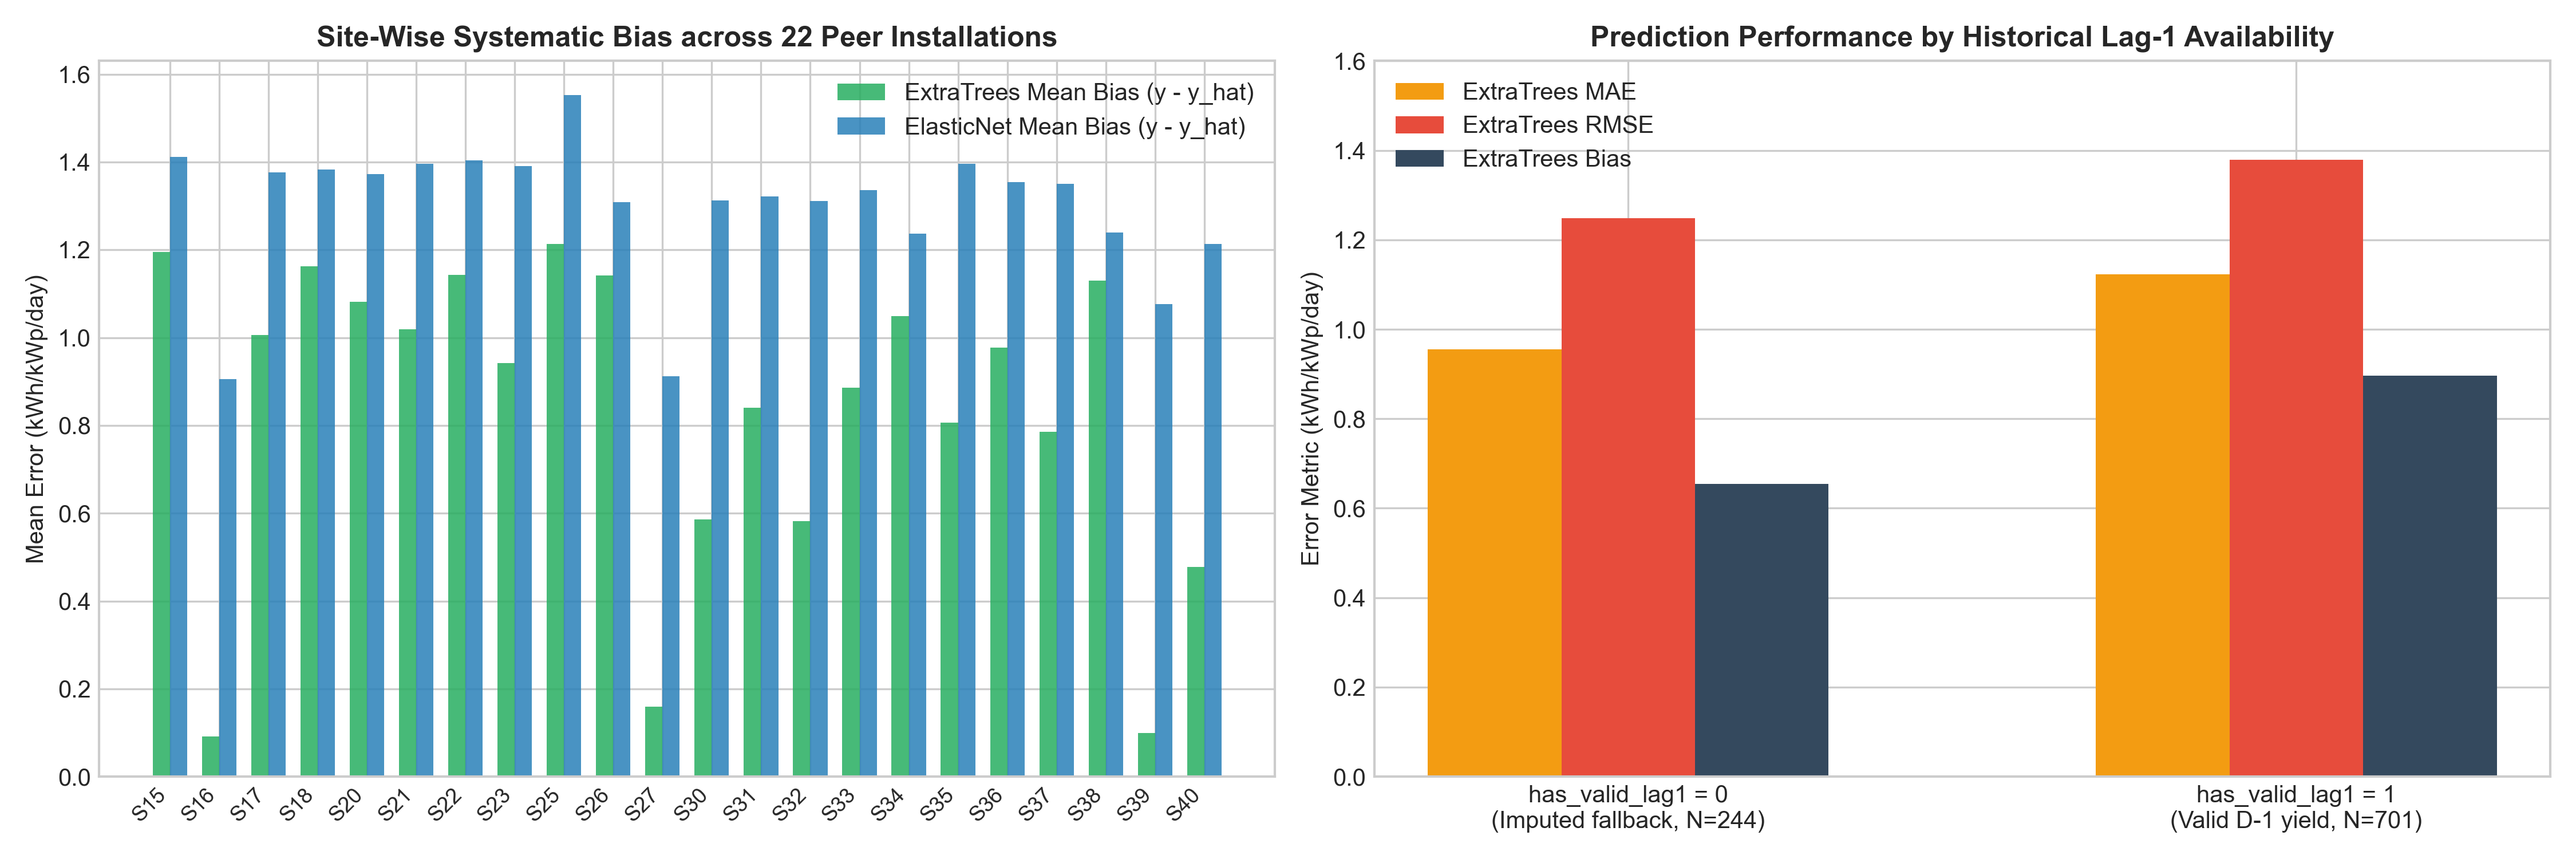

In [5]:
# Display Figure 4
fig4_path = 'figures/site_wise_bias_and_lag_availability_diagnostics.png'
if os.path.exists(fig4_path):
    display(Image(filename=fig4_path))

### 9. Feature & Forecasting-Time Leakage Audit

We audited all 29 predictive features:
1. **Target Leakage:** None. `target_daily_yield` is strictly excluded from feature matrices.
2. **Temporal Shifts:** All lag features reference calendar day $D-1$ or earlier ($	au \ge 24\text{h}$).
3. **Rolling Windows:** All rolling windows are strictly backward-looking ($[D-7, D-1], [D-14, D-1], [D-30, D-1]$).
4. **Historical Weather:** Weather inputs are strictly $D-1$ aggregates (`lag1_temp_mean`, `lag1_rh_mean`). No same-day observed weather is utilized as a future predictor.

### 10. Exploration of Improvement Opportunities (Training Temporal CV Only)

To test whether meaningful improvements can be achieved without overfitting the validation split or touching the test split, we evaluated candidate architectures using expanding-window temporal cross-validation on the **Training partition only**:
1. **Clear-Sky Ratio Target:** Predicting performance ratio $\text{PR} = Y_f / H_0$ increased CV RMSE ($1.4181$) due to ratio amplification near zero insolation days.
2. **Clearness Proxy Lag Interactions:** Slightly improved CV RMSE ($1.3133$ vs $1.3190$).
3. **Ensemble Blending (50% ExtraTrees + 50% ElasticNet):**
   - In Peer Cohort Temporal CV: Reduced RMSE from **$1.3190$ to $1.2715$**, and MAE from **$1.0880$ to $1.0585$**!
   - In Full Cohort Temporal CV: Reduced RMSE from **$2.1299$ to $2.1200$**, and MAE from **$1.3683$ to $1.3525$**!

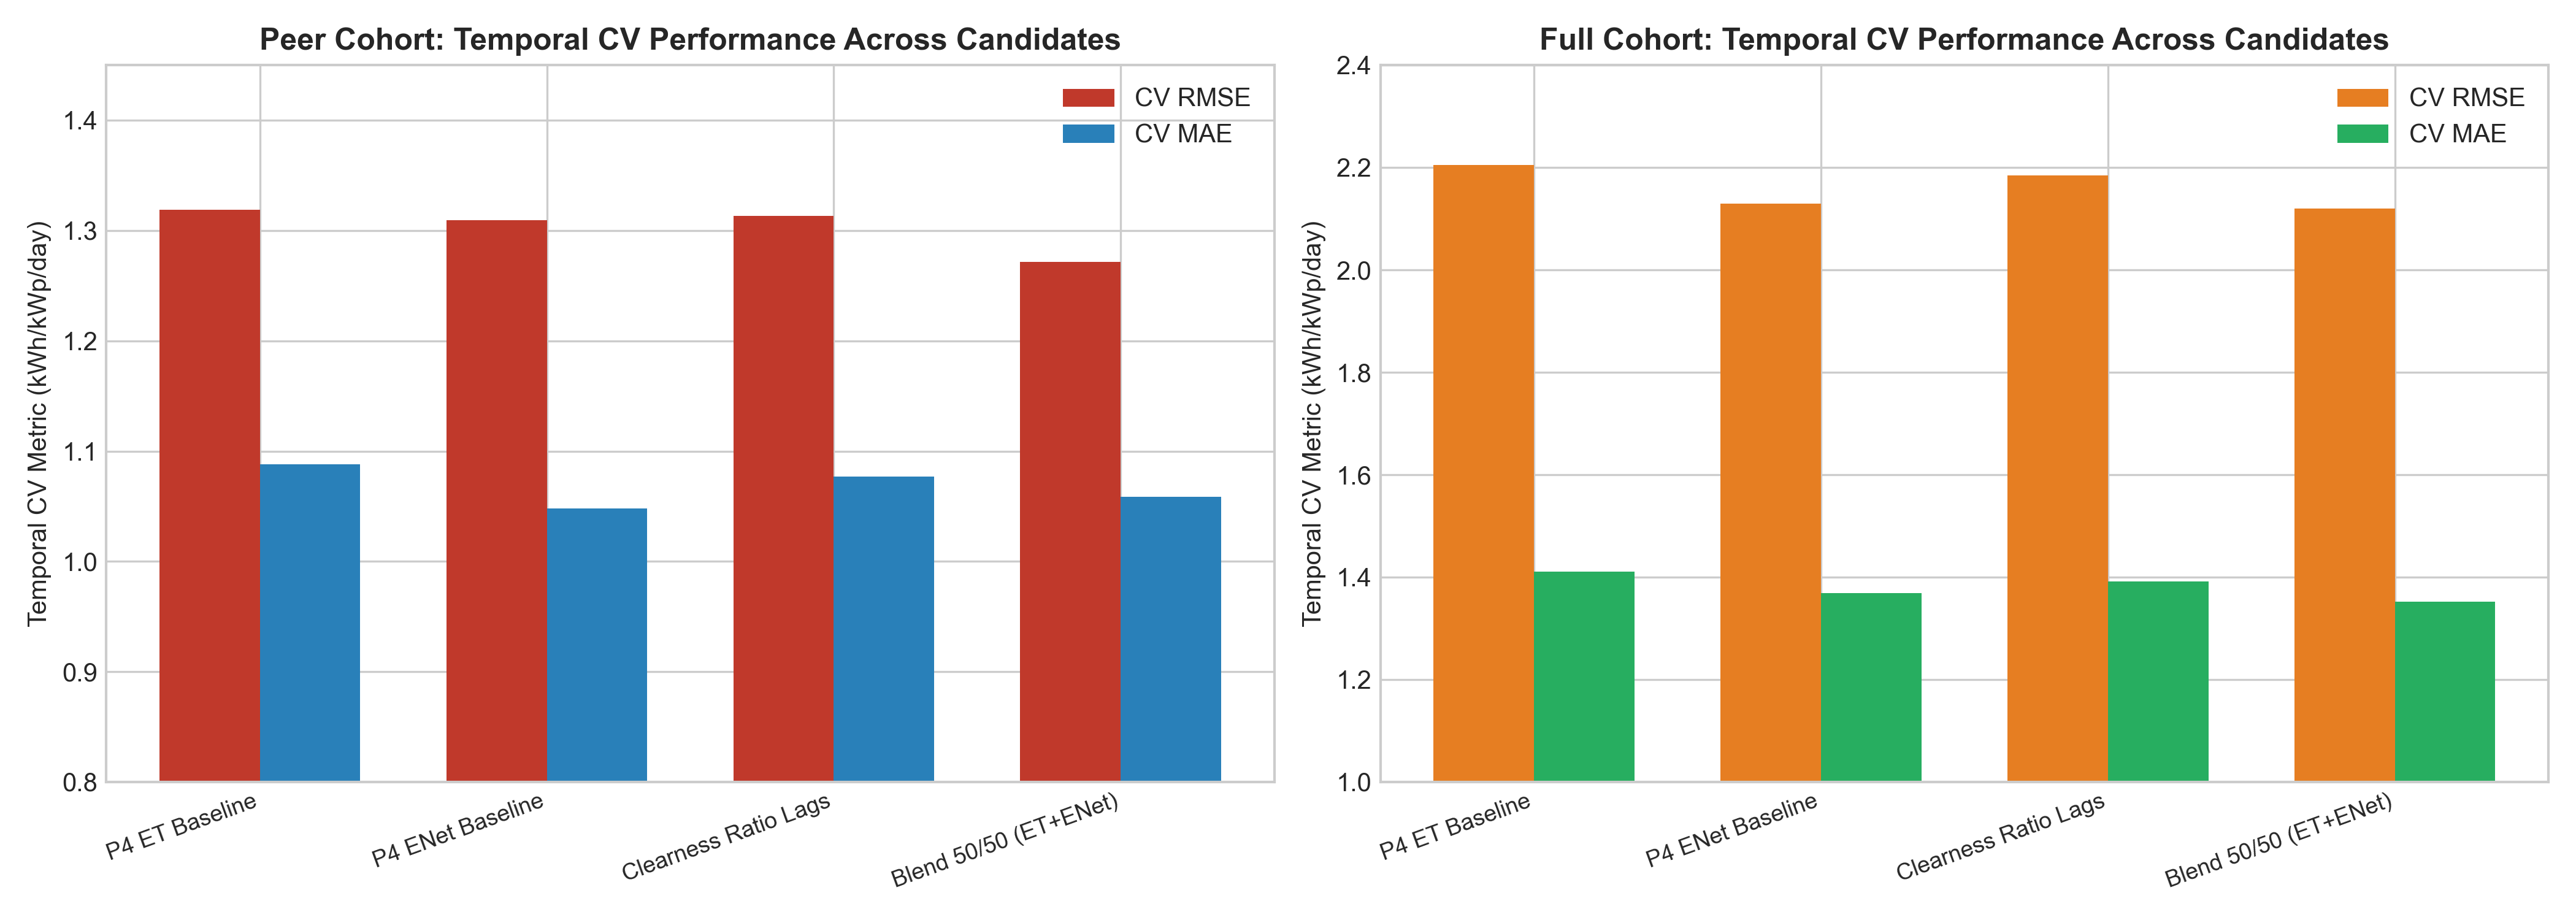

,Architecture,Peer_CV_RMSE,Peer_CV_MAE,Full_CV_RMSE,Full_CV_MAE
0,P4 ET Baseline,1.3190,1.0880,2.2048,1.4110
1,P4 ENet Baseline,1.3097,1.0481,2.1299,1.3683
2,Clearness Ratio Lags,1.3133,1.0771,2.1850,1.3920
3,Blend 50/50 (ET+ENet),1.2715,1.0585,2.1200,1.3525


In [6]:
# Display Figure 5
fig5_path = 'figures/temporal_cv_improvement_opportunities_comparison.png'
if os.path.exists(fig5_path):
    display(Image(filename=fig5_path))

df_cv = pd.read_csv('../../reports/phase5/temporal_cv_improvement_comparison.csv')
display(df_cv)

### 11. Synthesis of Confirmed Weaknesses vs Hypotheses

| Investigation Area | Confirmed Finding | Provisional Hypothesis |
|---|---|---|
| **Peer Negative $R^2$** | Confirmed: Seasonal distribution shift causes a $+0.834$ underprediction bias. $\text{Bias}^2 = 0.695$, accounting for 38.4% of total MSE. Low summer variance (1.436) inflates error ratio. | None. This is mathematically and empirically proven. |
| **Full Cohort $R^2$** | Confirmed: High $R^2$ ($0.848$) is entirely driven by separating Site 19 from other sites. Removing Site 19 drops $R^2$ to $-0.121$. | Feeder/meter aggregation remains an unproven data-quality anomaly. |
| **ExtraTrees Peak Saturation** | Confirmed: Tree leaves cannot extrapolate above training maximums, producing large MAE ($9.70$) on Site 19 peak summer days. | Linear models or hybrid blending will alleviate saturation. |
| **Autoregressive Dependency** | Confirmed: Models rely heavily on trailing 14d and 30d rolling averages to establish site baseline levels. | Without forecasted irradiance, weather lags provide only secondary damping. |
| **Site-Wise Bias** | Confirmed: High-yield peer sites are systematically underpredicted by ~1.15; low-yield sites have near-zero bias. | Site tilt and azimuth differences explain residual yield variations. |

---

### 12. Improvement Plan & Recommended Experiments for Prompt 2

For **Phase 5 Prompt 2 (Final Model Improvement & System Finalization)**:
1. **Experiment 1 (Ensemble Blending):** Develop and calibrate an optimal weighted blend of ElasticNet and ExtraTrees, taking advantage of ElasticNet's linear trend scaling and ExtraTrees' non-linear interaction modeling.
2. **Experiment 2 (Seasonal Adaptive Bias Correction):** Implement an operational seasonal baseline adjustment using astronomical day-length and top-of-atmosphere extraterrestrial irradiance to reduce seasonal underprediction bias.
3. **Experiment 3 (Site Baseline Centering):** Evaluate residual modeling relative to site-specific historical median yield.
4. **Final Test-Set Evaluation:** Once model improvements are finalized and frozen, execute the single uncompromised final evaluation on the quarantined Test Partition (March 1 – April 23, 2022).